# Using VAEAC for Video Prediction and camera motion prediction

In [1]:
import argparse
import os.path

import torch
import numpy as np
from torch import nn,optim
from videovae import VAEs
from torch import nn
from torch.utils.data import DataLoader  #Gives easier data management by creating mini batches etc.
from tqdm import tqdm
import matplotlib.pyplot as plt

/home/xu/xu/mmVAEAC_for_mobile_robot/mmVAEAC/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)
# The parser setting
parser = argparse.ArgumentParser()
parser = VAEs.add_model_specific_args(parser)
# parser.add_argument('--data_path', type=str, default='./datasets/livingroom/')
parser.add_argument('--data_path', type=str, default='./datasets/ATR_1F_3F_2024-12-25')

parser.add_argument('--sequence_length', type=int, default=16)
parser.add_argument('--resolution', type=int, default=64)
parser.add_argument('--batch_size', type=int, default=16)
parser.add_argument('--num_workers', type=int, default=8)
parser.add_argument('--LR_RATE', type=int, default=1e-4)
parser.add_argument('--NUM_EPOCHS', type=int, default=30)
args = parser.parse_args(args=[])
squence_length = 16
half_seq_len = int(squence_length/2)

cuda


## 1.Load the Datasets

### mobileRobo Dataset

In [3]:
from datasets.video_dataset import VideoDataset
# Load the Dataset
Dataset = VideoDataset
dataset = Dataset(args.data_path, args.sequence_length, train=True, resolution=args.resolution)

# dataloader for the trainning
dataloader_train = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=True
)

# dataloader for the evaluation
dataset = Dataset(args.data_path, args.sequence_length, train=False, resolution=args.resolution)
dataloader_val = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

metadata exists in: ./datasets/ATR_1F_3F_2024-12-25/train/metadata_16.pkl
metadata exists in: ./datasets/ATR_1F_3F_2024-12-25/test/metadata_16.pkl


## 2.Build the pretrained model

### 2.1 Build the proposal network, prior network and generative network

In [4]:
from videovae.pretrained_VAEAC import GaussianLoss, MobileNetDecoder, MobileNetEncoder
reonstruction_log_prob = GaussianLoss()
mobilenet_enc_proposal = MobileNetEncoder(96)
mobilenet_enc_prior = MobileNetEncoder(96)

# improve train computational stability by dividing the loss by this scale factor right before backpropagation
vlb_scale_factor = 64 ** 2 * 16

MLP_network_proposal = nn.Sequential(
    nn.Linear(1000, 1024)
)

MLP_network_prior = nn.Sequential(
    nn.Linear(1000, 1024)
)

MLP_network_vid = nn.Sequential(
    nn.Linear(512, 1024),
    
    nn.Linear(1024, 2048),
)

generative_network = MobileNetDecoder(96)


### 2.3 Load the pretrained checkpoint

In [5]:
from videovae.pretrained_VAEAC import VAEAC
MobileNet_pretrain = VAEAC(
    reonstruction_log_prob, mobilenet_enc_proposal, mobilenet_enc_prior,
                 MLP_network_proposal, MLP_network_prior, MLP_network_vid, generative_network,
).to(DEVICE)
# model = nn.DataParallel(model)
# modelData = './checkpoints/pretrained_mobilenet/600e_seg_4_2.pth.tar'
# MobileNet_pretrain.load_state_dict(torch.load(modelData)['model_state_dict'])

## 3.Build the mmVAEAC

In [6]:
reonstruction_log_prob = GaussianLoss()
mobilenet_enc_proposal = MobileNet_pretrain.mobilenet_enc_proposal
mobilenet_enc_prior = MobileNet_pretrain.mobilenet_enc_prior

# improve train computational stability by dividing the loss by this scale factor right before backpropagation
vlb_scale_factor = 64 ** 2 * 16

input_mot_channel = squence_length*4
mot_proposal_network = nn.Sequential(
    nn.Linear(input_mot_channel,input_mot_channel),
    nn.ReLU(),
    nn.Linear(input_mot_channel,128),
    nn.ReLU(),
    nn.Linear(128,256),
)

mot_prior_network = nn.Sequential(
    nn.Linear(input_mot_channel,input_mot_channel),
    nn.ReLU(),
    nn.Linear(input_mot_channel,128),
    nn.ReLU(),
    nn.Linear(128,256),
)

MLP_network_proposal = nn.Sequential(
    nn.Linear(1000 + 256, 1024),
    nn.Linear(1024, 1024),
)

MLP_network_prior = nn.Sequential(
    nn.Linear(1000 + 256, 1024),
    nn.Linear(1024, 1024),
)

MLP_network_vid = nn.Sequential(
    nn.Linear(512, 1024),
    nn.Linear(1024, 2048),

)

mot_generative_network = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Linear(256, 32),
    # nn.Sigmoid()
)

mobilenet_generative_network = MobileNet_pretrain.generative_network


## 4.Test the model

### Load a checkpoint

In [7]:
from videovae.mmVAEAC import mmVAEAC

# load the mmVAEAC pretrained model
model = mmVAEAC(
    reonstruction_log_prob, mobilenet_enc_proposal, mobilenet_enc_prior,
    mot_proposal_network, mot_prior_network, MLP_network_proposal, MLP_network_prior, MLP_network_vid, mot_generative_network, mobilenet_generative_network
).to(DEVICE)

# modelData = './checkpoints/pretrained_mmVAEAC/lvr_go3_60e.pth.tar'  
# modelData = './checkpoints/pretrained_mmVAEAC/atr_data_epoch_30.pth.tar'  
modelData = './checkpoints/pretrained_mmVAEAC/20250310_atr_data_no_pre_epoch_100.pth.tar'  

# 加载模型和权重
checkpoint = torch.load(modelData)
model.load_state_dict(checkpoint['model_state_dict'])

<All keys matched successfully>

### 4.1 The original input

In [8]:
valid_dataset = Dataset(args.data_path, args.sequence_length, train=True, resolution=args.resolution)

metadata exists in: ./datasets/ATR_1F_3F_2024-12-25/train/metadata_16.pkl


tensor(True)
[  0.    0.    0.    0.    0.    0.    0.  102.  153.  153.  153.  153.
   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.   76.5
 178.5 178.5 178.5 178.5 178.5 178.5 178.5 178.5 178.5 178.5 178.5 178.5
 178.5 178.5 178.5  76.5   0.    0.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.    0.    0.   51.   76.5   0.
   0.    0.    0.    0. ]
torch.Size([16, 64, 64, 3])
li:0.203 ang:0.000
li:0.203 ang:0.100
li:0.210 ang:0.200
li:0.203 ang:0.200
li:0.210 ang:0.000
li:0.203 ang:0.000
li:0.203 ang:0.000
li:0.203 ang:0.000


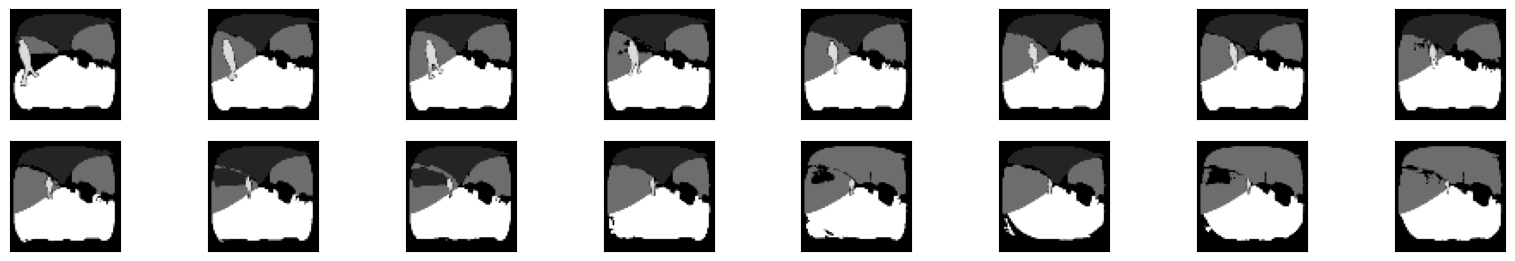

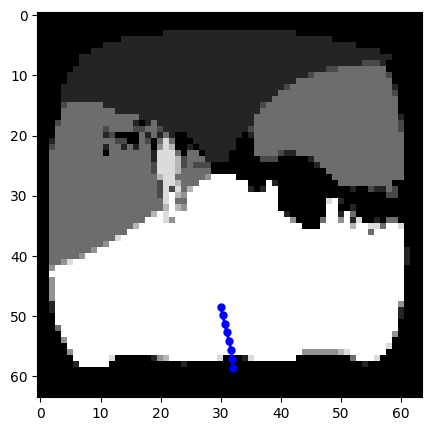

In [20]:
from videovae.utils import gray2color
from visual_utils import save_video
from eval.utils import is_human
camera_actions =[]
fig = plt.figure(figsize=(20, 10))
im_list = []
im_all = []
scale = 0.25
count = 0
step = 3
last_motion = 'stop'
idx = 62848
# 1200, 8000, 20000 
linear_gt = []
angle_gt = []

rec_vid_list = []
rec_mot_list = []

with torch.no_grad():
    # Load the batch and motion
    x,_,_ = valid_dataset[idx]

    batch, motion = dict.values(x)
    motion = motion.permute(1,0).to(DEVICE)
    rec_vid_list.append(batch)
    rec_mot_list.append(motion.reshape(1,squence_length,2))
    print(is_human(batch,0.01))
    ################## Three channels ##################################
    # vid = batch.view(-1,64,64,9)
    # vid_obstacle = vid[:,:,:,0] + vid[:,:,:,1] + vid[:,:,:,3] + vid[:,:,:,4] + vid[:,:,:,5]
    # vid_human = vid[:,:,:,6]
    # vid_floor = vid[:,:,:,7]
    # batch = torch.cat((vid_obstacle.unsqueeze(3), vid_human.unsqueeze(3), vid_floor.unsqueeze(3)), dim=3)
    ####################################################################

    # Change channels to 3 if there are only three classes
    batch = batch.reshape(1,squence_length,64,64,9).to(DEVICE)
    # transfer one-hot encoding to gray scale image
    batch_rgb = torch.argmax(batch, 4)
    C, T, H, W = batch_rgb.shape
    # (C,T,H,W) --> (T,H,W,C)
    video_batch = torch.concat((batch_rgb,batch_rgb,batch_rgb),0)
    # video saving
    batch_rgb = batch_rgb.squeeze().cpu().detach().numpy()
    save_video('origin.mp4',video_batch.reshape(1,3,squence_length,64,64),5)
    
    dec_rgb = gray2color(batch.squeeze().permute(0,3,1,2))
    dec_rgb = torch.clamp(dec_rgb, 0,1).permute(0,2,3,1)
    print(dec_rgb.shape)
    # The ground-truth unobserved actions (gt robot actions)
    for t in range(squence_length):
        if (t >= half_seq_len):            
            x = float(motion[t,0].mean())
            z = float(motion[t,1].mean())
            linear_gt.append(x)
            angle_gt.append(z)
            print('li:%.3f'%x,'ang:%.3f'%z)
    
    # Visualization of full information video inputs and gt robot actions
    for t in range(squence_length):
        im = torch.tensor(batch_rgb[t:t+1,:,:])
        im = im.view(H, W, 1)
        ax = fig.add_subplot(6, int(squence_length/2), int(squence_length/2)+t+1, xticks=[], yticks=[])
        if t==int(squence_length/2):
            map_x = 60 - 10*torch.cumsum(torch.tensor(linear_gt[::int(squence_length/16)]), dim=0)*np.cos(np.pi/4)
            map_z = 32 - torch.cumsum(torch.cumsum(torch.tensor(angle_gt[::int(squence_length/16)]), dim=0),dim=0)*np.cos(np.pi/4)
        ax.imshow(im[:,:],'gray')   

    fig1 = plt.figure(figsize=(20, 5))
    plt.plot(map_z.tolist(), map_x.tolist(), color='b', marker='o', linestyle='-',linewidth=2,markersize=5)
    im = torch.tensor(batch_rgb[half_seq_len-1,:,:]).view(H,W,1)
    plt.imshow(im, 'gray')

    

### 4.2 Generate the Sample

torch.Size([1, 18, 16, 64, 64])
li:0.203 ang:-0.016
li:0.210 ang:-0.047
li:0.217 ang:-0.060
li:0.219 ang:-0.032
li:0.219 ang:-0.007
li:0.217 ang:0.028
li:0.221 ang:0.017
li:0.217 ang:-0.020


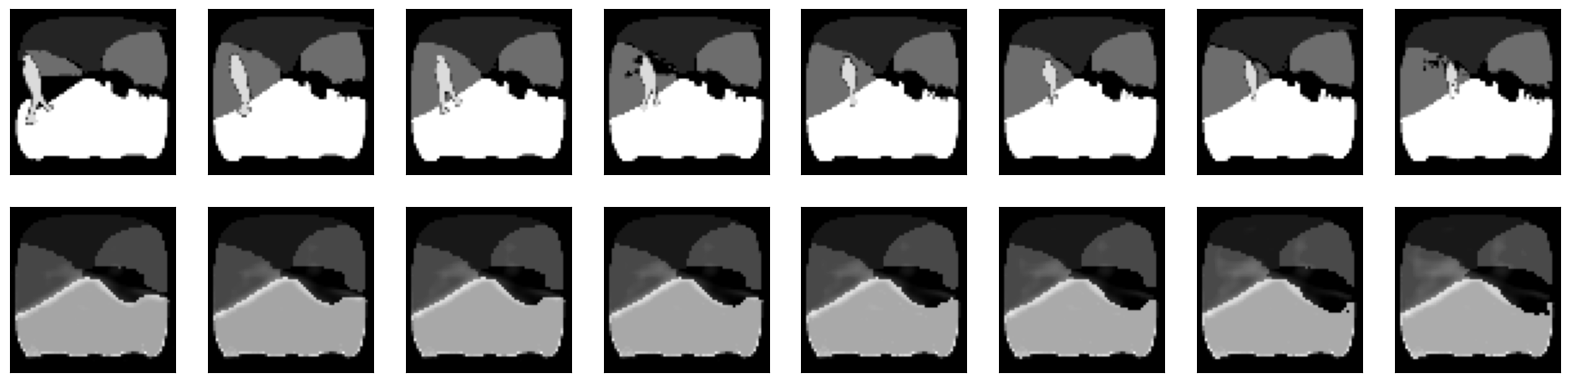

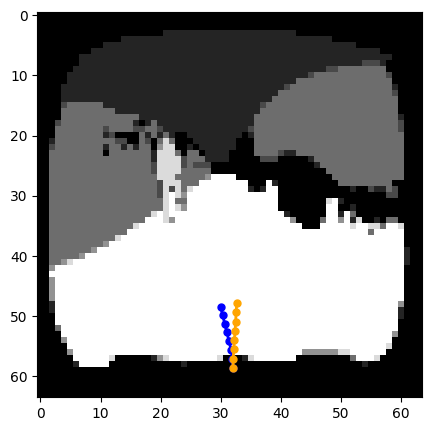

In [21]:
from videovae.pretrained_VAEAC import sampler
from videovae.mmVAEAC import VideoFixedSequenceGenerator
model.eval()
fig = plt.figure(figsize=(20, 15))
im_list = []
im_all = []
count = 0
camera_actions = []
linear_pd = []
angle_pd = []
mask_generator = VideoFixedSequenceGenerator()
for i in range(1):
    with torch.no_grad():
        # actions shape: (1,16,2)
        # video shape: (1,16,64,64,9)
        # Generate masks for video and actions
        mot = motion.reshape(1,squence_length,2)
        mask_batch = mask_generator(batch).to(DEVICE)
        mask_motion = mask_generator(mot)

        # Reconstruct the unobserved features
        rec_params_vid, rec_params_mot = model.generate_samples_params(batch, mot, mask_batch, mask_motion)
        print(rec_params_vid.shape)
        img_samples = sampler(rec_params_vid)
        mot_samples = rec_params_mot.reshape(squence_length,2)

        # Preprocess for visualization (8 observed frames + 8 reconstructed frames)
        model_input = batch.permute(0,4,1,2,3).to(DEVICE)
        mask = mask_batch.permute(0,4,1,2,3)
        model_input[mask.byte()] = 0
        img_samples[1-mask.byte()] = 0
        img_samples += model_input
        video_clip = img_samples

        rec_vid_list.append(video_clip.permute(0,2,3,4,1))
        rec_mot_list.append(mot_samples.reshape(1,squence_length,2))

        # Extract the channels presenting the intensity map of Human beings and the floor
        human_clip = img_samples[:,5]
        floor_clip = img_samples[:,6]

        predict_motion = mot_samples
        dec_vid = video_clip

        video_clip = torch.argmax(video_clip, 1)

        # Visualize the Human intensity
        C, T, H, W = video_clip.shape
        vid_clip = video_clip + human_clip

        # Save the video
        video_batch = torch.concat((vid_clip,vid_clip,vid_clip),0)
        save_video('demo.mp4',video_batch.reshape(1,3,squence_length,64,64),5)

        # (C,T,H,W) --> (T,H,W,C)
        video_clip = video_clip.permute(1,2,3,0).squeeze().cpu().detach().numpy()
        human_clip = human_clip.squeeze().cpu().detach().numpy()
        floor_clip = floor_clip.squeeze().cpu().detach().numpy()
        human_clip_img = human_clip
        video_clip = video_clip + 1*human_clip_img
        
        # The reconstructed robot actions
        for t in range(squence_length):
            if (t >= half_seq_len):
                # print(motion.shape)
                x = float(predict_motion[t,0])
                z = float(predict_motion[t,1]-0.5)
                linear_pd.append(x)
                angle_pd.append(z)
                print('li:%.3f'%x,'ang:%.3f'%z)
    
        # Visualization of reconstructed intensity maps and robot actions    
        for t in range(squence_length):
            im = torch.tensor(video_clip[t:t+1,:,:])
            im = im.view(H, W, C)
            # Calculate the human presence intensity
            if (t >= half_seq_len):
                sort_human_occur = sorted(human_clip[t].flatten(),reverse=True)
                sort_floor_occur = sorted(floor_clip[t].flatten(),reverse=True)
                mean_human_occur = np.array(sort_human_occur[:100]).mean()/6
                mean_floor_occur = np.array(sort_floor_occur[:50]).mean()
                prob_human = mean_human_occur/mean_floor_occur
        
            if t==int(squence_length/2):
                map_x_pd = 60 - 10*torch.cumsum(torch.tensor(linear_pd[::int(squence_length/16)]), dim=0)*np.cos(np.pi/4)
                map_z_pd = 32 - torch.cumsum(torch.cumsum(torch.tensor(angle_pd[::int(squence_length/16)]), dim=0),dim=0)*np.cos(np.pi/4)
            ax = fig.add_subplot(6, int(squence_length/2), int(squence_length/2)+t+1, xticks=[], yticks=[])
            ax.imshow(im[:,:,:3],'gray')  

        fig1 = plt.figure(figsize=(20, 5))
        plt.plot(map_z.tolist(), map_x.tolist(), color='b',marker='o', linestyle='-',linewidth=2,markersize=5)
        plt.plot(map_z_pd.tolist(), map_x_pd.tolist(), color='orange',marker='o', linestyle='-',linewidth=2,markersize=5)
        im = torch.tensor(video_clip[half_seq_len-1,:,:]).view(H,W,C)
        plt.imshow(im, 'gray')


li:0.203 ang:0.000
li:0.203 ang:0.100
li:0.210 ang:0.200
li:0.203 ang:0.200
li:0.210 ang:0.000
li:0.203 ang:0.000
li:0.203 ang:0.000
li:0.203 ang:0.000
li:0.203 ang:0.484
li:0.210 ang:0.453
li:0.217 ang:0.440
li:0.219 ang:0.468
li:0.219 ang:0.493
li:0.217 ang:0.528
li:0.221 ang:0.517
li:0.217 ang:0.480
Frame 1 Manhattan Distances: {'undetected_obs': tensor(0.0691), 'ceiling': tensor(0.1300), 'wall': tensor(0.1139), 'detected_furniture': tensor(0.0081), 'door': tensor(0.0031), 'Human': tensor(0.0254), 'Floor': tensor(0.0491)}


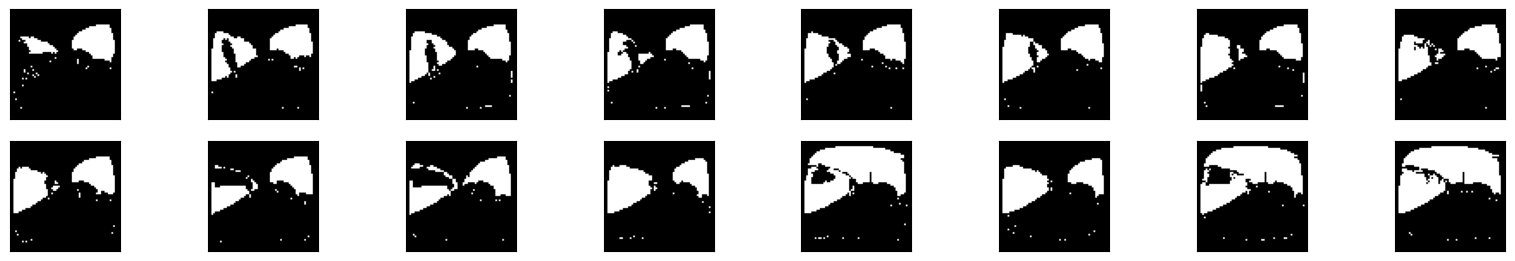

<Figure size 2000x500 with 0 Axes>

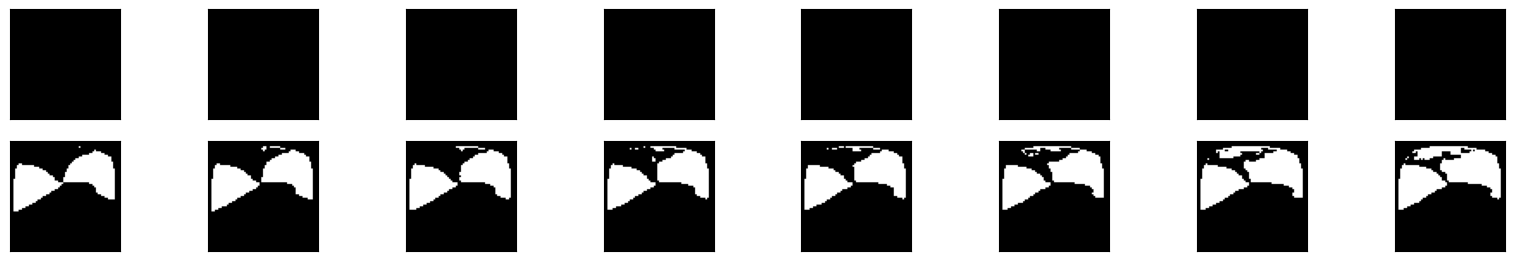

<Figure size 2000x500 with 0 Axes>

In [22]:
from eval.utils import manhattan_dist
manhattan_distance = manhattan_dist(args, rec_vid_list, rec_mot_list, 8, input_dim=9, vis_list = [False, False, True, False, False, False, False])


torch.Size([1, 9, 16, 64, 64])
[76.5 76.5 76.5 76.5 76.5 76.5 76.5 76.5 76.5 76.5  0.   0.   0.   0.
  0.  76.5  0.  76.5  0.   0.  76.5 76.5 76.5 76.5 76.5 76.5  0.   0.
  0.   0.  25.5 25.5 76.5 76.5 76.5 76.5 76.5 25.5 25.5 25.5 25.5 25.5
 25.5 25.5 25.5 25.5 25.5 76.5 76.5 25.5  0.   0.  25.5 76.5 76.5 76.5
 76.5 76.5 76.5 76.5 51.  76.5  0.   0. ]
torch.Size([16, 3, 64, 64])


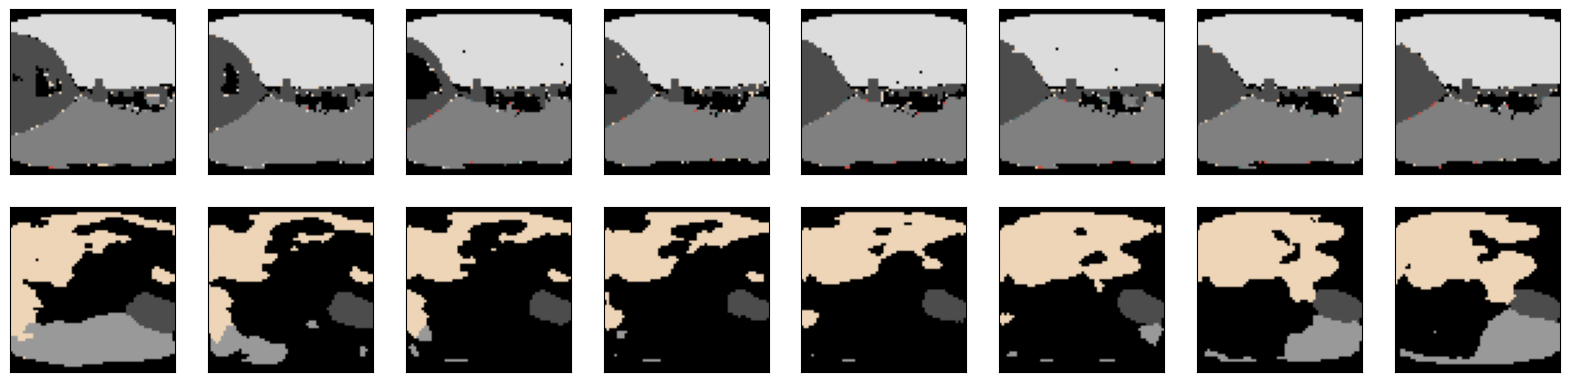

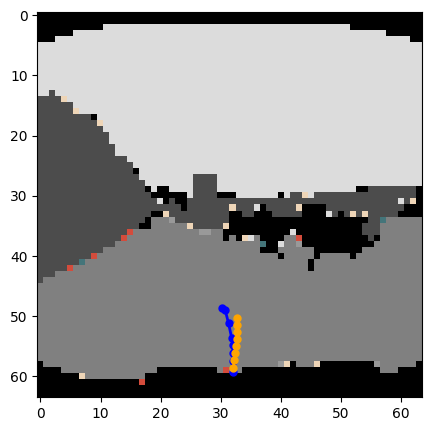

In [24]:
from videovae.utils import gray2color
print(dec_vid.shape)
fig = plt.figure(figsize=(20, 15))

dec_rgb = gray2color(dec_vid.squeeze().permute(1,0,2,3))
dec_rgb = torch.clamp(dec_rgb, 0,1)
print(dec_rgb.shape)
# Visualization of reconstructed intensity maps and robot actions    
for t in range(squence_length):
    im = torch.tensor(dec_rgb[t:t+1,:,:,:])
    im = im.squeeze().permute(1,2,0)
    
    if t==int(squence_length/2):
        map_x_pd = 60 - 10*torch.cumsum(torch.tensor(linear_pd[::int(squence_length/16)]), dim=0)*np.cos(np.pi/4)
        map_z_pd = 32 - torch.cumsum(torch.cumsum(torch.tensor(angle_pd[::int(squence_length/16)]), dim=0),dim=0)*np.cos(np.pi/4)
    ax = fig.add_subplot(6, int(squence_length/2), int(squence_length/2)+t+1, xticks=[], yticks=[])
    ax.imshow(im[:,:,:3])  

fig1 = plt.figure(figsize=(20, 5))
plt.plot(map_z.tolist(), map_x.tolist(), color='b',marker='o', linestyle='-',linewidth=2,markersize=5)
plt.plot(map_z_pd.tolist(), map_x_pd.tolist(), color='orange',marker='o', linestyle='-',linewidth=2,markersize=5)
im = torch.tensor(dec_rgb[half_seq_len-1,:,:,:]).squeeze().permute(1,2,0)
plt.imshow(im, 'gray')


### 4.3 Comparison between the predicted motion and ground truth

(-0.55, 0.55)

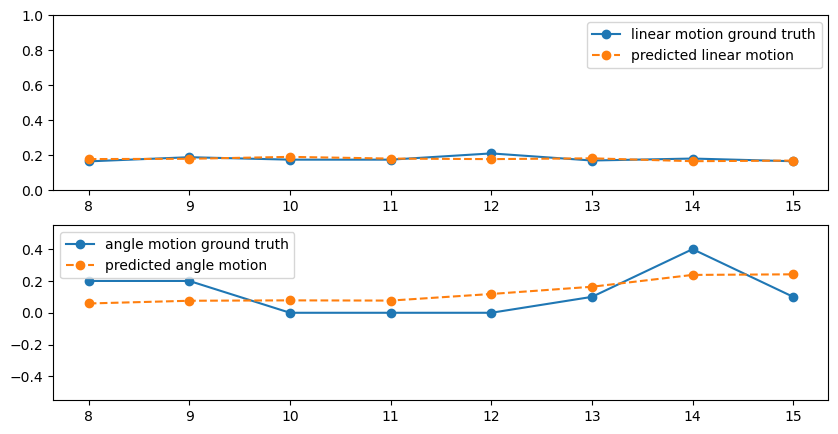

In [ ]:
fig = plt.figure(figsize=(10, 5))
x_list = list(range(half_seq_len,squence_length))
plt.subplot(2, 1, 1)
plt.plot(x_list,linear_gt, label='linear motion ground truth',marker='o', linestyle='-')
plt.plot(x_list,linear_pd, label='predicted linear motion', marker='o', linestyle='--')
plt.legend()
plt.ylim(0,1)

plt.subplot(2, 1, 2)
plt.plot(x_list,angle_gt, label='angle motion ground truth', marker='o', linestyle='-')
plt.plot(x_list,angle_pd, label='predicted angle motion', marker='o', linestyle='--')
plt.legend()
plt.ylim(-0.55, 0.55)
